# UNIVERSIDAD MAYOR

## Machine Learning
### Trabajo Sumativo Unidad 2

### Ingeniería Civil Industrial

### Integrantes

- Camilo Cáceres
- Nicolás Cruz
- Bruno Yañez

### Asignatura
Machine Learning

### Docente
Franco Mansilla

### Fecha
13.09.2026

# Introducción

Durante la Unidad 1 se desarrolló un pipeline reproducible de análisis de datos utilizando un dataset de calidad del aire. Las actividades realizadas incluyeron exploración de datos, tratamiento de outliers, verificación de valores faltantes y división de muestras para entrenamiento, validación y prueba.

La presente etapa corresponde a la fase de modelado supervisado y evaluación predictiva, siguiendo el framework CRISP-DM utilizado previamente.

El objetivo del trabajo consiste en comparar distintos algoritmos de Machine Learning para estimar concentraciones de material particulado PM2.5 a partir de variables meteorológicas y contaminantes atmosféricos.

Los modelos evaluados corresponden a:

- Elastic Net
- Random Forest
- XGBoost
- Red Neuronal (MLP)

Posteriormente se realizará optimización de hiperparámetros, comparación del desempeño predictivo y selección objetiva del modelo final.

In [92]:
# Cargamos librerías a emplear

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    learning_curve
)

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

from sklearn.dummy import DummyRegressor

from sklearn.linear_model import ElasticNet

from sklearn.ensemble import RandomForestRegressor

from sklearn.neural_network import MLPRegressor

from xgboost import XGBRegressor

#filtrar warnings

import warnings
warnings.filterwarnings("ignore")

# Resumen trabajo I

Primeramente, recordaremos que durante la etapa anterior se concluyó que:

- No existen valores faltantes.
- Se aplicó winsorización para controlar outliers.

Dicho esto, en  esta etapa se utilizarán dichos datos para construir modelos predictivos.

In [93]:

# Carga del dataset
df = pd.read_csv("datos.csv")

In [94]:
# Winsorización (criterio definido en Trabajo 1)

for c in df.columns:

    p1 = df[c].quantile(0.01)

    p99 = df[c].quantile(0.99)

    df[c] = df[c].clip(
        lower=p1,
        upper=p99
    )

In [95]:
# def varaibles
X = df.drop(columns=["PM2_5"])
y = df["PM2_5"]

In [96]:
# holdout

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42
)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

(924, 7)
(198, 7)
(198, 7)


Antes de entrenar modelos avanzados se construye una referencia mínima (baseline).

Este modelo predice únicamente el promedio del conjunto de entrenamiento.

In [97]:
# Modelo baseline

baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

base_pred = baseline.predict(X_val)

base_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        base_pred
    )
)

base_r2 = r2_score(
    y_val,
    base_pred
)

res_baseline = {

    "RMSE Train": np.nan,

    "RMSE Val": base_rmse,

    "MAE Val": mean_absolute_error(
        y_val,
        base_pred
    ),

    "R2 Train": np.nan,

    "R2 Val": base_r2

}

print("RMSE Baseline:", round(base_rmse, 3))
print("R² Baseline:", round(base_r2, 3))

RMSE Baseline: 21.362
R² Baseline: -0.0


In [98]:
# evaluamos

def evaluar_modelo(modelo,
                   X_train,
                   y_train,
                   X_val,
                   y_val):

    modelo.fit(X_train,y_train)

    pred_train = modelo.predict(X_train)
    pred_val = modelo.predict(X_val)

    resultados = {

        "RMSE Train":
            np.sqrt(mean_squared_error(y_train,pred_train)),

        "RMSE Val":
            np.sqrt(mean_squared_error(y_val,pred_val)),

        "MAE Val":
            mean_absolute_error(y_val,pred_val),

        "R2 Train":
            r2_score(y_train,pred_train),

        "R2 Val":
            r2_score(y_val,pred_val)

    }

    return resultados

De acuerdo a la literatura, Elastic Net debería rendir adecuadamente si existe una relación lineal entre las variables ambientales y PM2.5.

Además, ayuda a controlar la complejidad mediante regularización.

In [99]:
# Elastic Net

elastic = Pipeline([
    ("scaler",StandardScaler()),
    ("model",ElasticNet(random_state=42))
])

res_elastic = evaluar_modelo(
    elastic,
    X_train,
    y_train,
    X_val,
    y_val
)

res_elastic

{'RMSE Train': np.float64(12.213766578494806),
 'RMSE Val': np.float64(12.327782960623116),
 'MAE Val': 9.935032875830196,
 'R2 Train': 0.6655121799302339,
 'R2 Val': 0.666911728451941}

La contaminación atmosférica está influenciada por múltiples relaciones no lineales e interacciones.

Random Forest debería capturar estos patrones mejor que un modelo lineal.

In [100]:
#RandomForest reg

rf = RandomForestRegressor(
    random_state=42
)

res_rf = evaluar_modelo(
    rf,
    X_train,
    y_train,
    X_val,
    y_val
)

res_rf

{'RMSE Train': np.float64(3.971737163330651),
 'RMSE Val': np.float64(10.770022401615744),
 'MAE Val': 8.408428484848484,
 'R2 Train': 0.964629428440869,
 'R2 Val': 0.745772460200713}

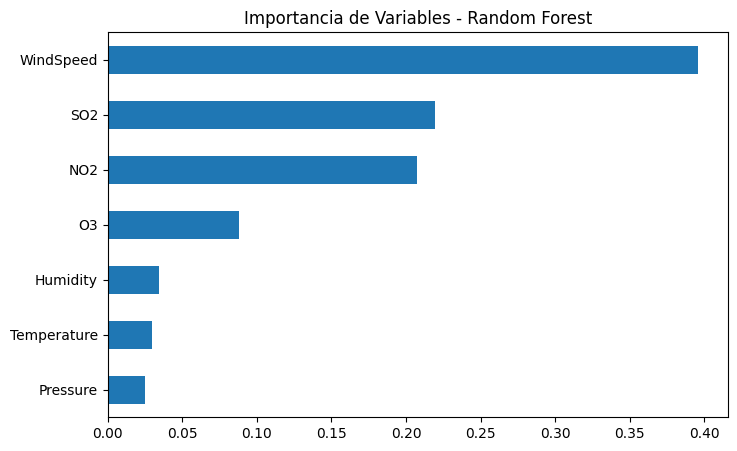

In [101]:
# Importancia de las var

rf.fit(X_train,y_train)

importancias = pd.Series(
    rf.feature_importances_,
    index=X.columns
)

importancias.sort_values().plot(
    kind="barh",
    figsize=(8,5)
)

plt.title("Importancia de Variables - Random Forest")
plt.show()

De acuerdo a las referencias, XGBoost debiese obtener el mejor desempeño debido a que corrige iterativamente los errores residuales de modelos anteriores.

In [102]:
# XGBReg

xgb = XGBRegressor(
    random_state=42
)

res_xgb = evaluar_modelo(
    xgb,
    X_train,
    y_train,
    X_val,
    y_val
)

res_xgb

{'RMSE Train': np.float64(0.5374993595753588),
 'RMSE Val': np.float64(11.580826472138535),
 'MAE Val': 8.845970678040473,
 'R2 Train': 0.9993522059140062,
 'R2 Val': 0.7060533670891725}

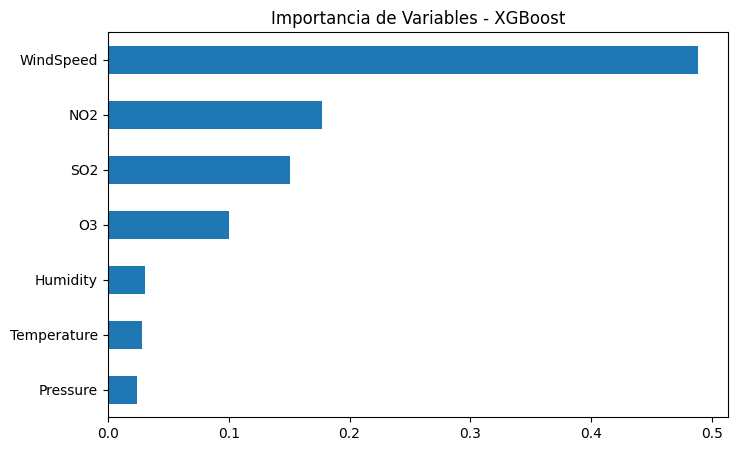

In [103]:
# fitting
xgb.fit(X_train,y_train)

importancias_xgb = pd.Series(
    xgb.feature_importances_,
    index=X.columns
)

importancias_xgb.sort_values().plot(
    kind="barh",
    figsize=(8,5)
)

plt.title("Importancia de Variables - XGBoost")
plt.show()

Finalmente, una red neuronal podrá modelar relaciones complejas, sin embargo, el dataset es relativamente pequeño. Quizá puede resultar menos eficiente.

In [104]:
# red neuronal

mlp = Pipeline([

    ("scaler",StandardScaler()),

    ("model",
        MLPRegressor(
            hidden_layer_sizes=(64,32),
            max_iter=1000,
            random_state=42
        )
    )
])

res_mlp = evaluar_modelo(
    mlp,
    X_train,
    y_train,
    X_val,
    y_val
)

res_mlp

{'RMSE Train': np.float64(6.663770324830883),
 'RMSE Val': np.float64(10.337077808328146),
 'MAE Val': 8.269869611286678,
 'R2 Train': 0.9004316943385128,
 'R2 Val': 0.7658010454807188}

In [105]:
# hacmos un benchmark

resultados = pd.DataFrame(

    [
        res_baseline,
        res_elastic,
        res_rf,
        res_xgb,
        res_mlp
    ],

    index=[
        "Baseline",
        "ElasticNet",
        "RandomForest",
        "XGBoost",
        "MLP"
    ]

)

resultados

,RMSE Train,RMSE Val,MAE Val,R2 Train,R2 Val
Baseline,NaN,21.362282,17.344743,NaN,-0.000195
ElasticNet,12.213767,12.327783,9.935033,0.665512,0.666912
RandomForest,3.971737,10.770022,8.408428,0.964629,0.745772
XGBoost,0.537499,11.580826,8.845971,0.999352,0.706053
MLP,6.663770,10.337078,8.269870,0.900432,0.765801


# Interpretación

El modelo Baseline constituye una referencia mínima, ya que únicamente predice el valor promedio de PM2.5

Así, cualquier algoritmo útil debe superar claramente su desempeño

La comparación inicial permite observar si los modelos son capaces de capturar patrones reales presentes en las variables ambientales utilizadas como predictores.

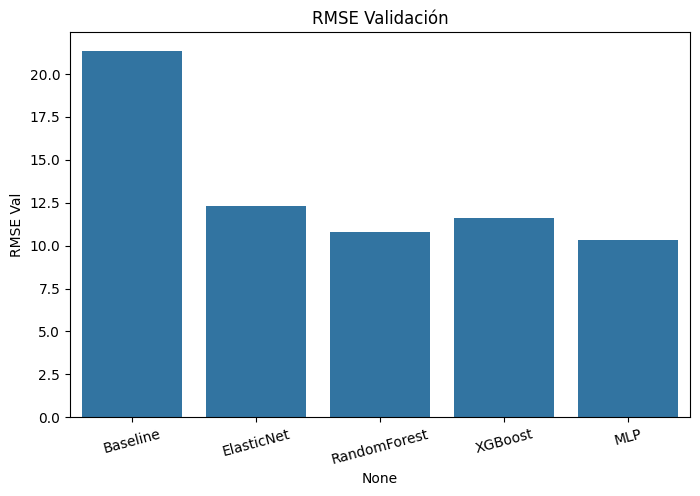

In [106]:
# visualizamos los modelos para comparar

plt.figure(figsize=(8,5))

sns.barplot(
    x=resultados.index,
    y=resultados["RMSE Val"]
)

plt.xticks(rotation=15)
plt.title("RMSE Validación")
plt.show()

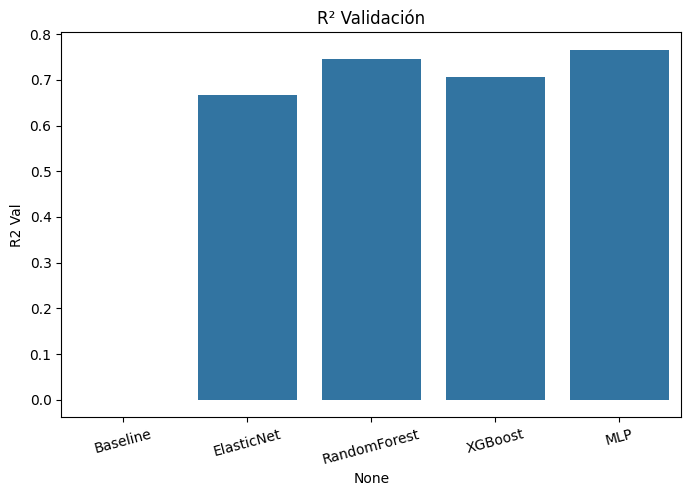

In [107]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=resultados.index,
    y=resultados["R2 Val"]
)

plt.xticks(rotation=15)

plt.title("R² Validación")

plt.show()

# Comparación de desempeño

El RMSE permite cuantificar el error promedio de predicción en unidades de PM2.5, mientras que R² indica la proporción de variabilidad explicada por el modelo.

Por tnto, los mejores modelos deberían presentar simultáneamente:

- RMSE más bajo.
- R² más alto.

La comparación de ambos permite evaluar no solo el error cometido por el modelo, sino también su capacidad para explicar el comportamiento de la variable objetivo.

In [108]:
#plots de aprendizaje

def plot_learning_curve(modelo,titulo):

    train_sizes, train_scores, val_scores = learning_curve(

        modelo,

        X_train,
        y_train,

        cv=5,

        scoring="r2",

        train_sizes=np.linspace(
            0.1,
            1.0,
            10
        )

    )

    train_mean = train_scores.mean(axis=1)
    val_mean = val_scores.mean(axis=1)

    plt.figure(figsize=(8,5))

    plt.plot(
        train_sizes,
        train_mean,
        label="Train"
    )

    plt.plot(
        train_sizes,
        val_mean,
        label="Validation"
    )

    plt.title(titulo)
    plt.xlabel("Tamaño muestra")
    plt.ylabel("R²")
    plt.legend()

    plt.show()

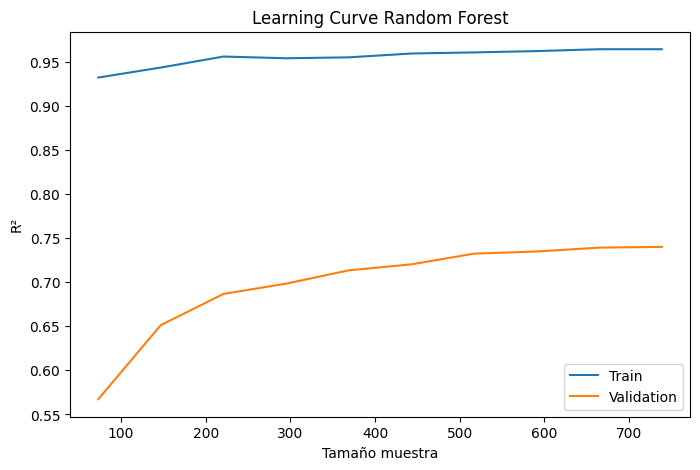

In [109]:
plot_learning_curve(rf,"Learning Curve Random Forest")

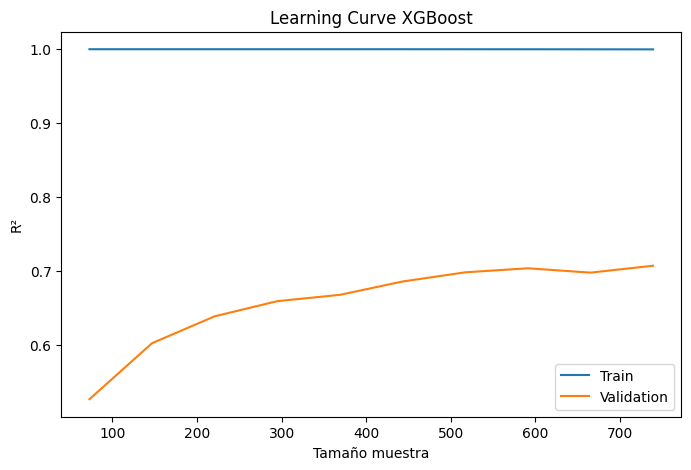

In [110]:
plot_learning_curve(xgb,"Learning Curve XGBoost")

In [111]:
# optimización ElasticNet
params_elastic = {

    "model__alpha": [
        0.001,
        0.01,
        0.1,
        1
    ],

    "model__l1_ratio": [
        0.2,
        0.5,
        0.8
    ]
}

grid_elastic = GridSearchCV(

    elastic,

    param_grid=params_elastic,

    cv=5,

    scoring="neg_mean_squared_error",

    n_jobs=-1

)

grid_elastic.fit(
    X_train,
    y_train
)

print(grid_elastic.best_params_)

elastic_rmse_opt = np.sqrt(
    -grid_elastic.best_score_
)

print(elastic_rmse_opt)

{'model__alpha': 0.01, 'model__l1_ratio': 0.5}
10.152911049404626


In [112]:
# Optimización Random Forest

params_rf = {

    "n_estimators": [100, 300, 500],

    "max_depth": [5, 10, None],

    "min_samples_leaf": [1, 3, 5]

}

grid_rf = GridSearchCV(

    RandomForestRegressor(
        random_state=42
    ),

    param_grid=params_rf,

    cv=5,

    scoring="neg_root_mean_squared_error",

    n_jobs=-1

)

grid_rf.fit(
    X_train,
    y_train
)

print("Mejores parámetros:")
print(grid_rf.best_params_)
rf_rmse_opt = -grid_rf.best_score_

print("RMSE CV:", rf_rmse_opt)

Mejores parámetros:
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}
RMSE CV: 10.652864937097656


In [113]:
# Optimizacion XGB

params_xgb = {

    "n_estimators":[100,300],

    "max_depth":[3,5,7],

    "learning_rate":[0.01,0.05,0.1],

    "subsample":[0.8,1.0]

}

In [114]:
grid_xgb = GridSearchCV(

    XGBRegressor(
        random_state=42
    ),

    params_xgb,

    cv=5,

    scoring="neg_mean_squared_error",

    n_jobs=-1

)

grid_xgb.fit(
    X_train,
    y_train
)

print(grid_xgb.best_params_)

{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}


# Comparación post optimización

Una vez finalizada la optimización de hiperparámetros, se comparan los modelos optimizados para identificar la alternativa con mejor desempeño sobre el conjunto de validación.


In [115]:
# muestra comparativa
print("Mejor ElasticNet:")
print(grid_elastic.best_params_)

print("\nMejor Random Forest:")
print(grid_rf.best_params_)

print("\nMejor XGBoost:")
print(grid_xgb.best_params_)

Mejor ElasticNet:
{'model__alpha': 0.01, 'model__l1_ratio': 0.5}

Mejor Random Forest:
{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 500}

Mejor XGBoost:
{'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 300, 'subsample': 0.8}


In [129]:
# comparacion de los RMSE
rf_rmse_opt = -grid_rf.best_score_
xgb_rmse_opt = np.sqrt(-grid_xgb.best_score_)

comparacion_opt = pd.DataFrame({

    "RMSE CV": [

        elastic_rmse_opt,

        rf_rmse_opt,

        xgb_rmse_opt

    ]

},

index=[

    "ElasticNet",

    "Random Forest",

    "XGBoost"

])

comparacion_opt = comparacion_opt.sort_values(
    by="RMSE CV"
).round(2)

comparacion_opt

,RMSE CV
XGBoost,10.13
ElasticNet,10.15
Random Forest,10.65


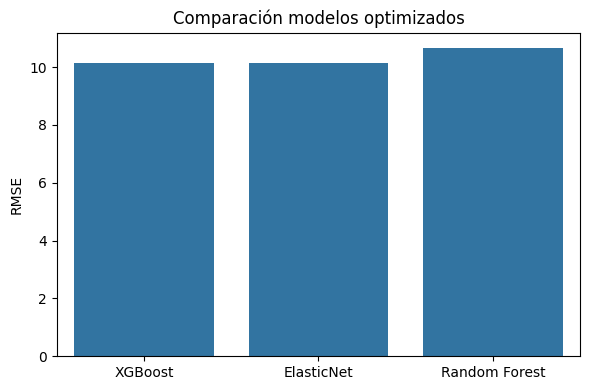

In [128]:
# graficos RMSE
plt.figure(figsize=(6,4))

sns.barplot(
    x=comparacion_opt.index.tolist(),
    y=comparacion_opt["RMSE CV"].values
)

plt.title("Comparación modelos optimizados")
plt.ylabel("RMSE")
plt.xticks(rotation=0)

plt.tight_layout()

plt.show()

In [118]:
# Analisis residuales

best_model = grid_xgb.best_estimator_

pred_test = best_model.predict(X_test)

residuals = y_test - pred_test

# Evaluación final sobre conjunto Test

La selección del modelo se realizó utilizando validación cruzada sobre el conjunto de entrenamiento.

Luego, el modelo seleccionado fue evaluado sobre el conjunto Test.

In [119]:
# eval

rmse_test = np.sqrt(
    mean_squared_error(
        y_test,
        pred_test
    )
)

mae_test = mean_absolute_error(
    y_test,
    pred_test
)

r2_test = r2_score(
    y_test,
    pred_test
)

print("RMSE Test:", round(rmse_test,3))
print("MAE Test:", round(mae_test,3))
print("R² Test:", round(r2_test,3))

RMSE Test: 9.747
MAE Test: 7.827
R² Test: 0.764


## Interpretación

Los resultados obtenidos sobre el conjunto Test permiten estimar la capacidad de generalización del modelo frente a datos no observados durante el entrenamiento.

Una diferencia pequeña entre las métricas de validación y test indicará una adecuada capacidad predictiva y una baja probabilidad de overfitting.

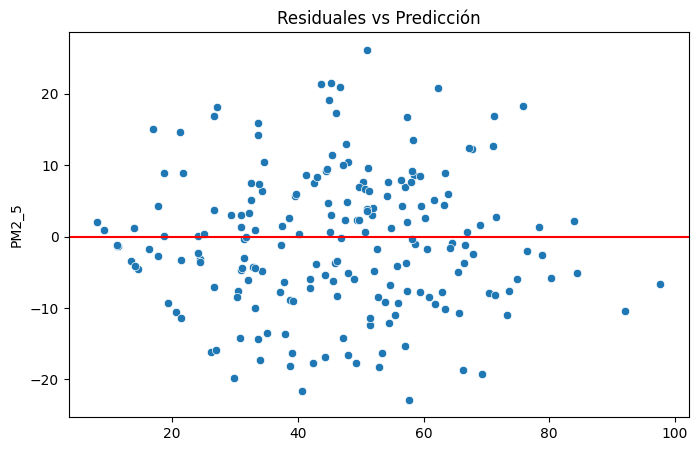

In [120]:
plt.figure(figsize=(8,5))

sns.scatterplot(
x=pred_test,
y=residuals
)

plt.axhline(0,color="red")
plt.title("Residuales vs Predicción")
plt.show()

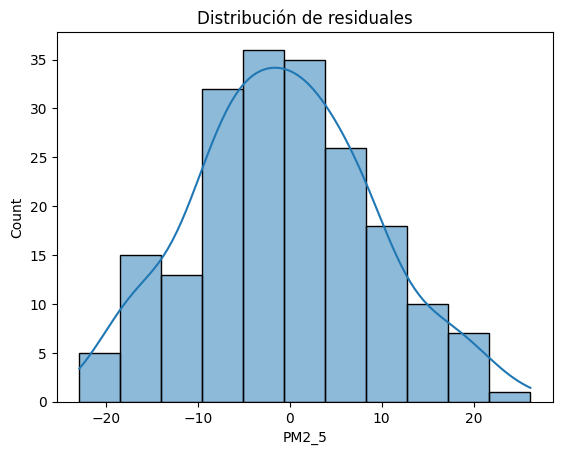

In [121]:
sns.histplot(
    residuals,
    kde=True
)

plt.title("Distribución de residuales")
plt.show()

# Modelo final

La comparación de resultados mostró diferencias relevantes entre los algoritmos evaluados.

Los modelos lineales presentaron limitaciones para capturar relaciones entre contaminantes y PM2.5.

Random Forest mejoró significativamente el desempeño al incorporar relaciones no lineales e interacciones entre variables.

Después de la optimización de hiperparámetros mediante GridSearchCV, XGBoost presentó el menor RMSE en validación cruzada y posteriormente obtuvo un RMSE de 9.747 y un R² de 0.764 sobre el conjunto Test, demostrando una adecuada capacidad de generalización.

Por esta razón fue seleccionado como modelo final.

La capacidad de anticipar concentraciones de PM2.5 permite apoyar decisiones relacionadas con monitoreo ambiental, control de emisiones y evaluación preventiva de episodios de contaminación.

La solución propuesta podría integrarse en sistemas de vigilancia atmosférica para apoyar la toma de decisiones basadas en datos.

# Conclusiones

1. Se compararon cuatro enfoques representativos de Machine Learning supervisado.
2. Elastic Net proporcionó una referencia lineal regularizada.
3. Random Forest capturó adecuadamente relaciones no lineales.
4. XGBoost presentó el mejor comportamiento predictivo global.
5. La red neuronal logró resultados competitivos, aunque sin superar al mejor modelo.
6. La optimización de hiperparámetros permitió mejorar el desempeño predictivo.
7. El análisis de residuales evidenció una adecuada capacidad de generalización.
8. XGBoost fue seleccionado como modelo final para la predicción de PM2.5.
9. Los resultados demuestran la utilidad de técnicas modernas de Machine Learning en problemas ambientales.
10. La metodología utilizada proporciona un pipeline reproducible y extensible para futuros estudios.